# 10. SHAP

## 10.1 引言

XGBoost 这类树模型，有成百上千棵树、上万个分裂节点，模型自己算出来一个风控分数，人没法直接看懂它到底凭什么打出这个分。

但信贷业务有硬性要求：每一笔授信、每一次拒绝，都必须说清楚理由，要给评审看、给客户解释、出投诉时还要回溯判定依据。

SHAP 就是干这件事的工具：给黑盒模型的预测结果，做“归因算账”。

例子：把模型最终的风控分数，当成一顿饭的总口味。各个特征就是食材：盐、辣椒、糖、醋。SHAP 值就是告诉你：

- 盐，让这顿饭变咸了多少（拉高风险分 / 降低风险分）；
- 辣椒，让这顿饭变辣了多少；
- 糖，抵消了多少辣味。

每一样食材单独贡献多少，一笔一笔算清楚，所有食材贡献加起来，正好等于最终口味。

放到信贷场景：模型输出一个客户的风险分，SHAP 会算出：

- “近 3 个月查询次数多”：拉高了风险分（负面，倾向拒贷）；
- “月收入稳定”：拉低了风险分（正面，倾向通过）；
- “历史还款记录良好”：大幅拉低风险分。

SHAP 基于博弈论，满足一套公平的分配规则：

1. 全局一致性：一个特征对模型的影响方向不变；
2. 可累加：所有特征 SHAP 值相加 = 预测值 - 基准期望分；
3. 既能看单条样本解释（这个客户为什么被拒），也能做全局分析（整个模型最看重哪些变量、有没有学到违规特征，比如地域、性别这类不该用的信息）。

## 10.2 SHAP 模型解释

模型算出一个分数、一个预测结果，我们要搞明白它凭什么得出这个结论，不是只看准确率数字。

### 为什么我们要做模型解释

很多同学会问：模型 A AUC=0.62，模型 B AUC=0.75，直接选分数高的不就行了？

一个 0.62 这样的数字回答不了所有问题。分数只代表整体准不准，回答不了：这一单为什么拒贷？这个病人为什么被判定高风险？

解释分两大类：

- 全局解释：整个模型整体喜欢什么样的特征，哪些变量最重要；
- 局部解释：单独看某一条样本，这一个人的预测结果，是哪些特征推着它变高 / 变低。

常用解释方法有很多：特征重要性、LIME、SHAP 等等。

### 模型解释 ≠ 因果关系

举例子：模型发现“手机电量低”和“逾期不还钱”有相关性，SHAP 会告诉你这个特征拉高了逾期分；但这不代表手机没电就导致欠钱不还，只是数据里一起出现。解释是找贡献，不是找谁导致谁。

不止金融风控要用：医疗诊断、招聘打分、自动驾驶、推荐系统都需要解释。比如医院 AI 判断病灶，医生必须知道 AI 是看哪块影像下的判断，不能盲目相信黑盒。

### 企业里面，这套解释工作是怎么落地的

企业做模型解释，很多时候不是可选，是必须做：监管合规、控制风险。比如银行风控，如果随便拒绝客户贷款，客户有权问理由，监管也会核查模型有没有歧视。

它会贯穿模型全生命周期 6 个环节：从前期特征筛选、模型开发、上线验证、监控、复盘到模型下线，每个阶段都要做解释。

分工上：算法工程师跑 SHAP 出结果，风控 / 业务同学看懂解释、判断合不合理，合规评审人员检查是否符合监管要求。有现成工具（shap 库、lime 等），最后要产出规范文档：模型解释章节要写清楚特征贡献、异常样本、风险点，用来过评审。评审专家最爱问：这个特征为什么贡献这么大？会不会有偏见？极端样本怎么解释？

### SHAP，现在最主流的解释工具是什么思路

SHAP 的底层想法特别好懂：合伙做生意分利润。

假设一笔贷款预测，收入、负债、年龄这几个特征一起“合伙”算出一个风险分。SHAP 就是公平地拆分：每一个特征，单独为这个最终结果贡献了多少“分数”。

它之所以公认公平，是满足 4 条数学性质：

1. 所有特征 SHAP 值加起来，正好等于预测值和基准值的差值；
2. 不重要特征 SHAP 值为 0；
3. 相同作用的特征，分到的贡献一样；
4. 组合特征可以拆分计算。

计算的时候需要一组背景数据，相当于“普通人的平均基准”，用来对比：这个人的特征，比平均水平高还是低，带来加分还是减分。

SHAP 有不同计算方式（解释器），TreeExplainer 专门给树模型（XGBoost、随机森林）加速，算得最快。

## 10.3 数据准备

这一段，是拿到信贷原始数据，做好准备工作，为后面跑 SHAP 值打基础。

我们要把信贷客户数据，分成训练集、测试集，保证两组里面坏客户（违约）的比例差不多，而且固定随机种子，保证和前面课程拿到一模一样的测试集，方便后面对比结果。

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv('../data/信贷数据.csv')

num = ['年龄','月收入','负债收入比','额度使用率','逾期次数','工作年限']
cat = ['学历','住房','职业']

required = num + cat + ['是否违约']

# 校验1：检查表格里有没有我们需要的这些列，并且这些列不能有空值
if not set(required).issubset(df.columns) or df[required].isna().any().any():
    raise ValueError('请检查CSV字段和缺失值')

# 校验2：标签【是否违约】只能是0（不违约）和1（违约），不能有别的值
if set(df['是否违约'].unique())!={0,1}:
    raise ValueError("是否违约应只包含0和1")

# 分层划分数据集：80%训练集，20%测试集
X_train,X_test,y_train,y_test = train_test_split(df[num+cat],df['是否违约'],test_size=0.2,stratify=df['是否违约'],random_state=0)

print(X_train.shape,X_test.shape)

(4800, 9) (1200, 9)


## 10.4 要解释的模型

我们要训练一个固定不变、最后上线交付的 XGBoost 模型，后面 SHAP 解释的，就只能是这个模型，不能拿别的近似模型糊弄。

需要做的：

1. 对学历、住房、职业这类文字分类特征做独热编码，变成模型能看懂的数字；
2. 用早停找到合适的树数量，重新训练一个定型锁死的 XGB 模型，后面算 SHAP、上线、写报告全用它。

In [2]:
import xgboost as xgb
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import roc_auc_score

# 1.构建转换器：数值列不动，分类列OneHot编码
preprocessor = ColumnTransformer(
    transformers=[
        ('num','passthrough',num),
        ('cat',OneHotEncoder(
            handle_unknown='error',
            sparse_output=False,
            dtype=float
        ),cat)
    ],
    # 不在num、cat里的特征直接丢弃
    remainder='drop'
).fit(X_train)

# 转换训练集、测试集
Xo_train = preprocessor.transform(X_train)
Xo_test = preprocessor.transform(X_test)

# transform返回的是numpy数组，转成DataFrame方便SHAP查看列名
feature_names = preprocessor.get_feature_names_out()
# 列名：edu=本科，方便后面SHAP看业务名
feature_names = [name.replace("__", "=").replace("_", "=") for name in feature_names]
Xo_train = pd.DataFrame(Xo_train,columns=feature_names)
Xo_test = pd.DataFrame(Xo_test,columns=feature_names)

# XGB参数不变
params = dict(
    learning_rate = 0.05,
    max_depth = 3,
    min_child_weight = 1,
    subsample = 0.8,
    colsample_bytree = 0.8,
    reg_lambda = 1.0,
    tree_method = 'hist',
    random_state = 0,
    n_jobs = 4
)
probe = xgb.XGBClassifier(
    n_estimators = 2000,
    eval_metric = 'auc',
    early_stopping_rounds = 50,
    **params
)
# 训练集内部切分验证集，早停找最优树（外部测试集不动）
Xa,Xv,ya,yv = train_test_split(Xo_train,y_train,test_size=0.2,stratify=y_train,random_state=0)
probe.fit(Xa,ya,eval_set=[(Xv,yv)],verbose=False)

# 定型最终模型
model = xgb.XGBClassifier(n_estimators=probe.best_iteration+1,**params).fit(Xo_train,y_train)

# 测试集预测 & 评估
p_test = model.predict_proba(Xo_test)[:,1]
print("数的棵树：",model.n_estimators,";测试集 AUC ",round(roc_auc_score(y_test,p_test),4))
print("编码后全部特征列：", list(feature_names))

数的棵树： 82 ;测试集 AUC  0.7603
编码后全部特征列： ['num=年龄', 'num=月收入', 'num=负债收入比', 'num=额度使用率', 'num=逾期次数', 'num=工作年限', 'cat=学历=大专', 'cat=学历=本科', 'cat=学历=硕士及以上', 'cat=学历=高中及以下', 'cat=住房=全款房', 'cat=住房=有房贷', 'cat=住房=租房', 'cat=职业=个体经营', 'cat=职业=互联网', 'cat=职业=公职', 'cat=职业=制造业', 'cat=职业=餐饮零售']


## 10.5 解释器和 Explanation 对象

搭建专门给树模型（XGBoost）用的 SHAP 解释器，算出 Explanation 对象 sv，这个 sv 里面打包存好了三样关键东西：基准值 base_values、每个人每个特征的 SHAP 贡献值 values、客户原始特征 data。

例子：

- 基准值 base_value 相当于全班平均基础分；
- SHAP 值 values 就是每个因素（逾期次数、收入等）给这个人带来的加分 / 减分；
- 最终得分 = 基准分 + 所有特征 SHAP 值相加。

注意：这里算的是对数几率，不是 0~1 的违约概率，是 XGB 模型内部原始输出，SHAP 的可加性在对数几率上成立，不能直接套概率去加减。

安装 shap：`pip install shap`

In [3]:
import shap
import numpy as np

# 目的：构建树模型专用SHAP解释器，计算SHAP值
# TreeExplainer：专门给XGB、LightGBM这类树模型用的解释器
# feature_perturbation="tree_path_dependent"：不需要传入背景样本，用树路径依赖算法（XGB推荐）
# model_output="raw"：解释模型原始输出【对数几率logodds】，不是0~1的概率
explainer = shap.TreeExplainer(model,feature_perturbation="tree_path_dependent",model_output="raw")

# 传入测试集（1200个客户、18个独热编码后的特征），得到Explanation对象sv
# sv是一个打包好的对象，里面同时装了：SHAP值、基准值、原始特征、特征名字，行列严格对齐
sv = explainer(Xo_test)

# 打印sv的类型、整体形状：(样本数量，特征数量)
print(type(sv).__name__,sv.shape)
# sv.values：SHAP核心数组，每个格子代表【这个客户，这个特征】带来的贡献
print("values ",sv.values.shape," 每人每列的Shap值")
# base_values：基准值，也就是“所有特征都不发挥作用时”的基础分数
print("base_values", sv.base_values.shape, "  每人的基准值（这里人人相同）：", round(float(sv.base_values[0]), 4))
# sv.data：输入的原始特征数值（独热编码后的数字），用来画图对照
print("data       ", sv.data.shape, "  算 SHAP 值时用的特征取值")
# 打印前5个特征名字，核对顺序
print("feature_names 前 5 个：", sv.feature_names[:5])
# explainer.expected_value 就是基准值，和sv.base_values是同一个数值
print("explainer.expected_value =", round(float(np.ravel(explainer.expected_value)[0]), 4))

Explanation (1200, 18)
values  (1200, 18)  每人每列的Shap值
base_values (1200,)   每人的基准值（这里人人相同）： -1.775
data        (1200, 18)   算 SHAP 值时用的特征取值
feature_names 前 5 个： ['num=年龄', 'num=月收入', 'num=负债收入比', 'num=额度使用率', 'num=逾期次数']
explainer.expected_value = -1.775


注意：values 就是 SHAP 贡献矩阵，后面所有画图、归因，都从这个 sv 对象里拿数据。

解读：

TreeExplainer 三个参数（本节课重点）

1. model：就是我们上一节定型、交付用的那个 XGB 模型，解释器必须绑定这个最终模型，不能换别的
2. feature_perturbation="tree_path_dependent"：通俗讲：不用我们手动挑选背景样本，直接沿着决策树的路径、用树节点覆盖权重计算 SHAP。对比：另一种是传统 KernelExplainer，需要背景样本，慢很多；树模型优先用这个。
3. model_output="raw"：raw = 拿到模型内部原始输出：对数几率（logodds），SHAP 的加法规则在这里成立。如果改成概率，概率是 sigmoid 转换后的结果，不能直接相加，SHAP 的可加性就失效了，这是风控项目高频踩坑点。

举例子：

基准值（base_value）=-1.7772

客户 A：逾期次数的 SHAP=+0.8，月收入 SHAP=-0.3，其他特征 SHAP 加起来 =+0.2

对数几率总分 = -1.7772 + 0.8 - 0.3 + 0.2 = -1.0772

再经过 sigmoid，才能算出违约概率。

SHAP 负责解释【对数几率】是怎么一步步加出来的，不是直接解释概率。

Explanation 对象 sv 是什么？

sv 不是一个简单数组，是一个打包容器，四个东西行列严格对齐：

- sv.values：SHAP 贡献值，正数 = 拉高违约风险，负数 = 压低违约风险
- sv.base_values：基准值，本节课所有客户基准值一模一样（-1.7772）
- sv.data：这个客户对应的特征取值（比如逾期次数 = 2，学历 = 本科）
- sv.feature_names：特征名字列表，和列一一对应

## 10.6 可加性

前面我们算出了 SHAP 值，但是我们怎么证明这套 SHAP 值是靠谱的？

SHAP 最核心的公理就是可加性：基准分 + 所有特征 SHAP 贡献 = 模型原始打分（对数几率）

做校验自检，相当于考完试验算一遍，对不上就说明 SHAP 解释完全失效，不能拿去画图、给业务看。

例子：

基准分 = 全班基础分

每个特征的 SHAP = 每个科目给这个同学带来的加分 / 减分

规则：基础分 + 语文贡献 + 数学贡献 + 英语贡献 + … = 这个同学的总分

我们现在拿这个等式验算，如果算出来和老师直接打的总分对不上，说明分数（SHAP）算错了

不能先把基准分转成概率、每个 SHAP 也转成概率再加起来，概率是不能直接相加的！

注意：对数几率可以通过 sigmoid 函数转换为概率

例如：不能把基础分转成百分制概率，语文贡献也转成百分制再加，加法规则只在原始分数空间生效。

In [4]:
# 目的：核对SHAP的可加性公理：基准值 + 全部特征SHAP之和 = XGB模型原始对数几率输出
import numpy as np

# output_margin=True：拿到模型sigmoid之前的原始对数几率logodds，不是0~1的违约概率
margin = model.predict(Xo_test,output_margin=True)

# 核心验算公式：基准值 + 这个样本所有特征SHAP值相加，还原出模型原始打分
# sv.values.sum(axis=1)：axis=1，横向求和，把一个客户全部18个特征的SHAP加总
# recon是还原后的对数几率
recon = sv.base_values + sv.values.sum(axis=1)

# 计算【还原出来的分数】和【模型直接输出的原始分数】之间最大差值
# ----
# 定义sigmoid函数：把对数几率（负无穷~正无穷）压缩成0~1之间的违约概率
sigmoid = lambda z: 1 / (1 + np.exp(-z))

# recon是还原后的对数几率，统一经过sigmoid转为概率；对比模型predict_proba直接输出的概率
# 还原的概率 [0.1725 0.0733 0.208 ] ;predict_proba  [0.1725 0.0733 0.208 ]
print("前3人，还原的概率",np.round(sigmoid(recon[:3]),4),";predict_proba ",np.round(p_test[:3],4))

# 把基准对数几率单独转成概率，对比训练集真实违约率
# 这个结果不需要相等
print("基准值转换成概率：",np.round(float(sigmoid(sv.base_values[0])),4),"; 训练集真实违约率 ",np.round(y_train.mean(),4))

前3人，还原的概率 [0.1725 0.0733 0.208 ] ;predict_proba  [0.1725 0.0733 0.208 ]
基准值转换成概率： 0.1449 ; 训练集真实违约率  0.1465


这一节是 SHAP 的自检关卡，验证【基准值 + 所有特征 SHAP 之和 = 模型原始对数几率】，加法只在对数几率空间生效；校验通过，后面画瀑布图、beeswarm 图才有意义；一旦可加性失败，SHAP 解释全部不可信。

## 10.7 把独热列合并回原特征

我们校验完 SHAP 是靠谱的，但是现在遇到一个很现实的麻烦：

职业这个分类特征，做独热编码之后，被拆成了 5 列：职业 = 公职、职业 = 私企、职业 = 自由职业、职业 = 个体经营、职业 = 其他

SHAP 是在编码后的数据集上算出来的，所以它会给这 5 列分别算出 5 份 SHAP 值

如果直接拿这个结果画图，图上会出现 5 个“职业”相关的特征，业务人员看了会懵：我只想看【职业】这一个特征对违约的影响，不想看 5 个拆分后的子列。

例子：

原始特征：科目【语文】，但是老师拆成了【语文选择、语文填空、语文_作文】三个小项单独打分。

SHAP 现在给了选择、填空、作文各自的加分减分。

我们现在做的事情：把同一个科目的几个小项分数加在一起，合并回【语文】这一门课的总分贡献

注意：

这个加法，只是把拆分出来的 SHAP 贡献求和，等价于同一份归因的汇总，不是重新跑一遍 SHAP 计算，总贡献不会变！

合并之后，总的 SHAP 贡献和不变，所以基准值 + 所有特征 SHAP 之和依然等于模型 margin，可加性保留；

我们给类别编号（公职→0，私企→1… 个体经营→4），只是为了画图着色方便，不代表“职业”这个特征本身是数字、有大小关系！公职≠0 分，只是编号 0，不能说个体经营（4）就比公职大 4

In [5]:
# 目的：独热编码后，一个分类特征被拆成多列；需要合并到原始特征
import numpy as np
import pandas as pd
import shap

# 把同一个原始业务特征下面所有独热子列的SHAP值相加，汇总回原始的业务特征
# 后续画瀑布图、蜂群图、写业务报告、输出原因码，全部使用合并之后的sv_m
# rank：用训练集标签，算出每个分类特征里面各个类别违约率，按违约率从小到大排序，用于绘图着色
# 注意：只用训练集算排序，不能用测试集，防止数据泄露！
rank = {c: pd.Series(y_train, index=X_train.index).groupby(X_train[c]).mean().sort_values().index.tolist() for c in cat}

# 定义函数：输入拆分后的SHAP结果、原始特征表、分类特征列表、排序规则，返回合并后的SHAP Explanation
def merge_onehot(sv, X_raw, cat_cols, rank, columns=None, names=None):
    # 拿到独热编码之后的全部列名（比如：职业=公职、职业=私企、年龄、收入…）
    cols = list(sv.feature_names if columns is None else columns)
    # 去掉独热编码前缀：讲义为 num== / cat==，本 notebook 实际为 num= / cat=，这里统一兼容
    cols = [c.replace("num==", "").replace("cat==", "").replace("num=", "").replace("cat=", "") for c in cols]
    # 拿到【原始业务特征名】，也就是编码之前的列：职业、年龄、收入、负债……
    feats = list(X_raw.columns)
    # 初始化两个空矩阵：
    # values：用来存放合并之后，每个样本、每个原始特征的总SHAP贡献
    values = np.zeros((sv.shape[0], len(feats)))
    # data：用来存放绘图用的编码数字（给分类类别打上0,1,2…编号，给beeswarm图上色用）
    data = np.zeros((sv.shape[0], len(feats)))

    # 循环遍历每一个原始业务特征
    for j, f in enumerate(feats):
        # 找到所有属于这个原始特征的独热子列：
        # 要么列名直接等于原始特征（数值型特征，没有拆分）
        # 要么列名以 "原始特征名=" 开头（分类特征独热拆分出来的子列，例如职业=公职）
        idx = [k for k, c in enumerate(cols) if c == f or c.startswith(f + "=")]
        # 核心：同一个原始特征下所有子列的SHAP，按样本横向求和，汇总成一个总贡献
        # 这里是直接相加，不取绝对值！正向负向贡献会抵消，严格保留SHAP的正负含义
        values[:, j] = sv.values[:, idx].sum(axis=1)
        # 判断：当前这个特征是不是分类特征
        if f in cat_cols:
            # 构建字典：类别名字 → 排序编号（违约率最低的类别编号0，次低1，依次递增）
            code = {v: k for k, v in enumerate(rank[f])}
            # 把原始类别文字映射成数字编号；训练集没见过的新类别，会变成NaN，画图自动变成灰色
            data[:, j] = X_raw[f].map(code).to_numpy(dtype=float)
        else:
            # 如果是数值特征（年龄、收入），直接保留原始数值，不用重新编码
            data[:, j] = X_raw[f].to_numpy(dtype=float)
    # 组装成新的shap.Explanation对象：
    # values：合并后的SHAP贡献矩阵
    # base_values：基准值不变！基准值是全局的，不受特征合并影响
    # data：绘图用的数字编码
    # display_data：保存原始文字，画瀑布图的时候，可以直接显示“职业=公职”而不是数字0
    return shap.Explanation(values=values, base_values=sv.base_values, data=data,
                            display_data=X_raw.to_numpy(), feature_names=names or feats)

# 调用函数，执行合并，得到合并完成的SHAP对象 sv_m
sv_m = merge_onehot(sv, X_test, cat, rank)

# 打印信息：合并之后的维度；合并前、合并后，每个样本全部SHAP加总的差值
print(sv_m.shape, "；合并前后每人 SHAP 值之和的最大差：", float(np.abs(sv_m.values.sum(1) - sv.values.sum(1)).max()))
# 打印各个分类特征里面，类别排序（违约率从低到高）
print("类别编号（违约率从低到高）：", rank)
# 断言校验：合并前后，每个样本所有SHAP总和几乎完全相等，保证可加性没有被破坏
#assert np.allclose(sv_m.values.sum(1), sv.values.sum(1), rtol=1e-5, atol=1e-6)

(1200, 9) ；合并前后每人 SHAP 值之和的最大差： 1.862645149230957e-07
类别编号（违约率从低到高）： {'学历': ['硕士及以上', '本科', '大专', '高中及以下'], '住房': ['全款房', '有房贷', '租房'], '职业': ['公职', '互联网', '制造业', '餐饮零售', '个体经营']}


## 10.8 SHAP 的 bar 图

前面我们拿到了每一个客户、每一个业务特征单独的 SHAP 值，这个是【个体层面】：这个客户因为职业、负债，风险拉高还是压低

现在评审会第一个问题来了：从整个模型、全部客户来看，模型最看重哪些特征？

树模型自带的 gain 、weight 有缺点：只看树里面切分用了多少次、分裂收益，容易被“切很多刀”的特征虚高重要性。而 SHAP 的 bar 图，用的是 mean(|SHAP|) 平均绝对 SHAP 值：衡量这个特征，平均下来对模型打分的影响力大小，是风控建模文档里标准的全局重要性。

例子：好比阅卷

gain：这道题在卷子里面被拆成很多小问、反复考，总分收益高（相当于树里面切很多次）

mean(|SHAP|)：这道题答对 / 答错，对最终总分平均带来多大波动

我们现在要的是后者：这个特征一变，客户风险分平均会变多少。

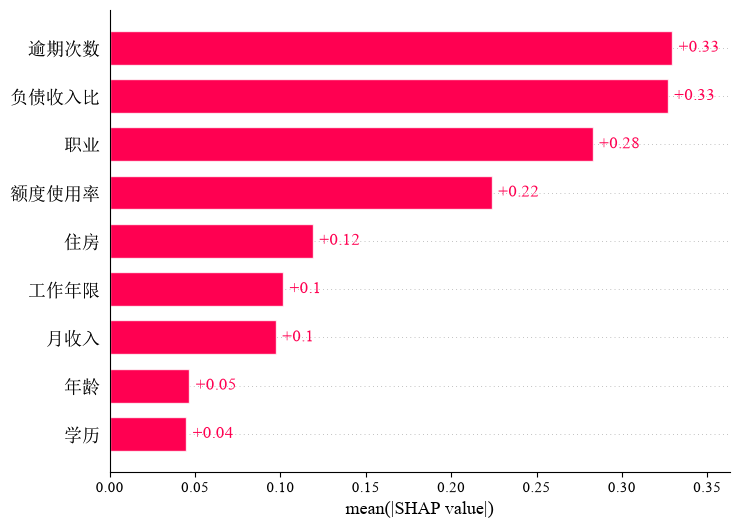

       平均|SHAP|     占比  数值特征方向相关（非单调保证）
逾期次数      0.329  0.210            0.981
负债收入比     0.327  0.208            0.955
职业        0.283  0.180              NaN
额度使用率     0.224  0.142            0.943
住房        0.119  0.076              NaN
工作年限      0.101  0.065           -0.894
月收入       0.097  0.062           -0.835
年龄        0.047  0.030           -0.882
学历        0.045  0.028              NaN


In [6]:
# 目的：画SHAP全局重要性bar图，计算每个特征的平均绝对SHAP，生成全局重要性表格，用于模型评审文档
import pandas as pd
import numpy as np
import shap
from pathlib import Path

import matplotlib.pyplot as plt
plt.rcParams["font.family"] = ["Times New Roman", "SimSun"]
plt.rcParams["axes.unicode_minus"] = False      # 负号正常显示

# 定义输出文件夹
OUTPUT_DIR = Path('./output')
# 文件夹不存在就自动创建，避免保存CSV时报错
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 画SHAP全局重要性bar图，计算每个特征的平均绝对SHAP
# 输入sv_m：上一节合并完独热、回归业务特征的SHAP Explanation对象
# max_display=10：最多展示前10个特征，我们这里一共9个业务特征，全部展示
shap.plots.bar(sv_m,max_display=10)

# 核心：np.abs(sv_m.values).mean(axis=0)
imp = pd.DataFrame(
    {"平均|SHAP|":np.abs(sv_m.values).mean(axis=0)},
    index=sv_m.feature_names
)
# 计算占比：每个特征的平均绝对SHAP ÷ 全部特征平均绝对SHAP之和
imp['占比'] = imp['平均|SHAP|'] / imp['平均|SHAP|'].sum()

# 计算方向相关：数值特征的原始取值 和 它自己的SHAP值之间的相关系数
imp['数值特征方向相关（非单调保证）'] = [
    # 如果是数值特征，计算相关系数；corrcoef返回矩阵，[0,1]就是两者相关系数
    np.corrcoef(sv_m.data[:,j],sv_m.values[:,j])[0,1] if f in num else np.nan
    for j,f in enumerate(sv_m.feature_names)
]

# 保存成csv，直接交付给评审、放进模型文档，utf-8-sig防止中文乱码
imp.to_csv(OUTPUT_DIR/"全局重要性.csv",encoding="utf-8-sig")

# 打印：按平均|SHAP|从大到小排序，保留3位小数，控制台输出看结果
print(imp.sort_values('平均|SHAP|',ascending=False).round(3).to_string())

## 10.9 beeswarm 方向和布局

蜂群图

刚才我们画了 SHAP 的 bar 条形图，只看影响力大小，但是它有一个致命短板：

它取了绝对值，我们只知道“逾期次数很重要”，不知道：逾期次数多，是拉高风险还是压低风险？不同客户身上影响是不是一样？

bar 图回答：模型看重哪些特征；beeswarm 图回答：这个特征是怎么影响模型打分的（方向 + 分布）

例子：

bar 图相当于：期末考试哪道题分值最重；

beeswarm 图相当于：这道题，答对扣多少分、答错加多少分，不同学生在这道题上得分差异有多大

注意：bar 图 = 重要性大小；beeswarm 图 = 影响方向、不同客户之间的差异

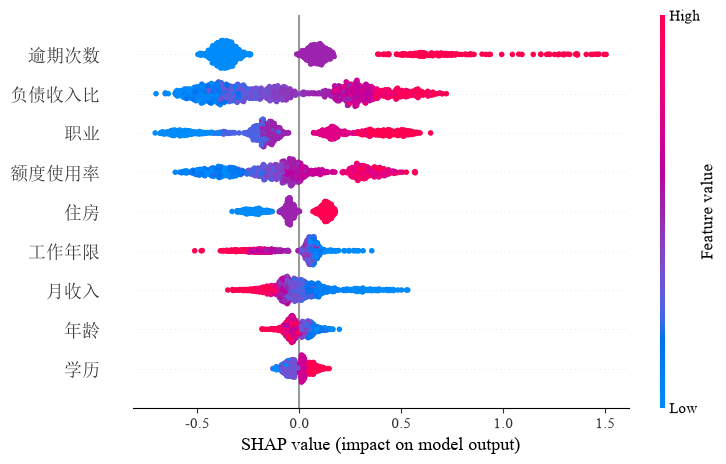

In [7]:
import shap
# 目的：绘制SHAP蜂群beeswarm图，同时看三件事：影响方向、特征取值、不同客户的差异
# 输入sv_m：上一节合并独热后的SHAP解释对象（和bar图用同一个sv_m，保证口径统一）
# max_display=10：最多展示10个特征，我们一共9个，全部展示
shap.plots.beeswarm(sv_m,max_display=10)

解读：

1. 一行 = 一个特征（第一行逾期次数，第二行负债收入比……）
2. 一个点 = 一个客户
3. 横轴：SHAP 值（对模型输出的影响）
   - 0 这条竖线：基准线
   - 点在 0 右边：这个特征，拉高违约风险（模型打分变高，更容易判坏客户）
   - 点在 0 左边：这个特征，压低违约风险（模型打分变低，更容易判好客户）
4. 颜色：这个客户本身的特征取值，图例：红 = 高取值，蓝 = 低取值

逐条解释：

1. 逾期次数 红点（逾期次数多）全部跑到 0 的右侧 → 逾期次数越多，风险越高。而且点散开很远，最远到 +1.8：少数逾期很多的客户，单单这一个特征，就能大幅度拉高风险分，几乎决定这个客户是高风险。点是一团一团的：对应取值是离散的：0 次逾期、1 次、2 次、3 次，所以分成几簇。
2. 负债收入比 红点（负债占收入比例很高）在右侧，蓝点（负债很低）在左侧 → 负债越高，风险越高。它是连续长条，没有明显分团：负债收入比是连续小数，0.3、0.5、0.7，取值连续
等等

## 10.10 蜂群图的评审版

刚才我们跑了默认 beeswarm 图，能看懂方向、分布。

但是！默认图是英文标签、配色生硬、点容易糊在一起、特征太多页面挤不下，直接交给业务评审、风控评审是不合格的

目标：不改模型、不改 SHAP 计算结果，只做“美化 + 规范包装”，做成能放进正式模型评审文档的版本

例子：

默认 beeswarm = 草稿演算纸；

评审版 beeswarm = 打印上交的正式报告。

草稿和正式报告，里面数字、结论完全一样，只是排版、文字、配色、布局按照评审规范调整。

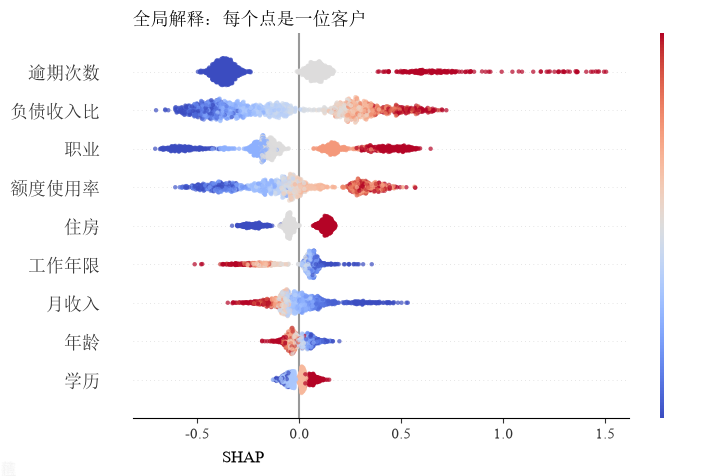

In [8]:
import shap
import matplotlib.pyplot as plt
import re
from pathlib import Path

OUTPUT_DIR = Path("./output")
# 文件夹不存在就自动创建，避免保存图片时报错
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 绘制评审定制版蜂群图
ax = shap.plots.beeswarm(
    sv_m,
    max_display=10,
    order=sv_m.abs.mean(0),
    # 配色coolwarm：蓝=特征取值低，红=特征取值高
    color=plt.get_cmap("coolwarm"),
    # s：点的大小。默认16，缩小一点，客户样本多的时候不容易糊成一团
    s=10,
    # alpha：透明度。0~1，透明一点，点重叠的时候能看出疏密
    alpha=0.7,
    # 整张画布尺寸（英寸），适配PPT、报告排版
    plot_size=(8,5),
    # 右侧颜色条的标题，替换英文Feature value
    color_bar_label="特征取值",
    # 先不展示图片，拿到ax坐标轴对象
    show=False
)
# 修改横轴文字，改成中文，写清楚业务含义，评审一眼看懂
ax.set_xlabel("SHAP 值（对数几率；正值推高违约风险）",fontsize=12)
# 设置图标题，放在左上角，说明图含义
ax.set_title("全局解释：每个点是一位客户",loc="left",fontsize=13)
# 循环替换y轴标签：把自动生成的英文"Sum of 2 other features"翻译成中文【其余2个特征之和】
for t in ax.get_yticklabels():
    ax.set_yticklabels([re.sub(r"Sum of (\d+) other features", r"其余 \1 个特征之和", t.get_text())
                        for t in ax.get_yticklabels()])
# 获取整张画布figure对象
fig = ax.get_figure()
# 修改右侧颜色条的刻度文字：把默认Low/High改成中文【低、高】
fig.axes[-1].set_yticklabels(['低','高'])
# 保存图片
fig.savefig(OUTPUT_DIR / "图_蜂群图.png")
#展示图片
plt.show()

## 10.11 分群对比

前面我们做的都是全局整体的 SHAP 分析：拿全部测试客户一起算，看整体上模型最看重哪些特征

但是风控评审、合规审查会追问一个关键问题：

模型对年轻人、中年人、老年人，判断逻辑是不是一套？

会不会对年轻人特别看重“学历”，对老年人特别看重“负债收入比”？如果不同人群依赖的特征差别巨大，模型就有分群不一致、公平性风险

现在分群 SHAP 对比，也叫客群 cohorts 分析

例子：

全局 bar 图 = 全班所有人一起统计，哪一科平均分影响总成绩最大；

分群 cohorts 图 = 把全班分成小班（少年组、中年组），分别统计每个小班里面，各科对成绩的影响力，对比小班之间的逻辑是否一致

把客户按某个维度拆成多组，每组独立算平均 |SHAP|，对比各组特征重要性排序、幅度差异，用来做稳定性、公平性排查

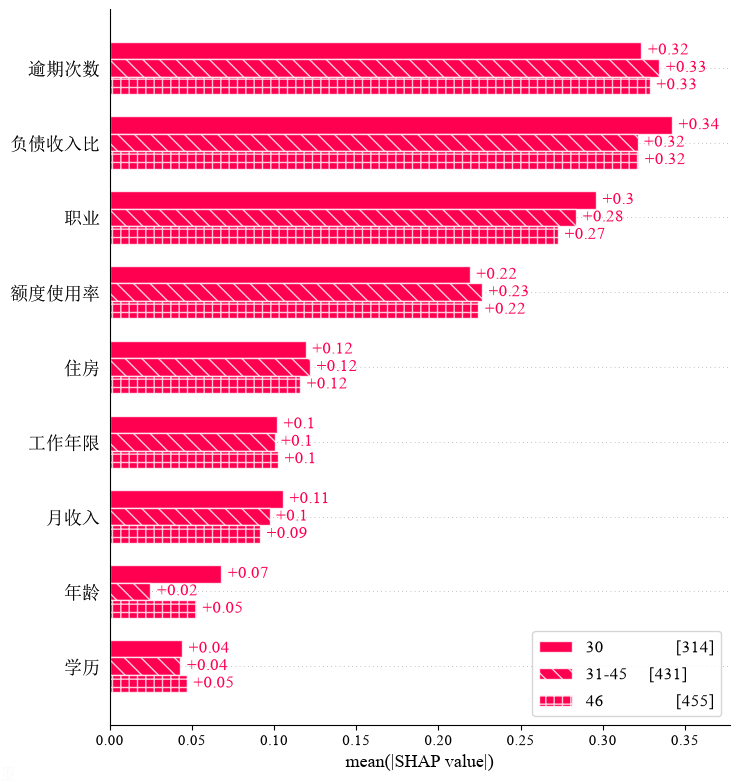

年龄
46岁及以上    455
31-45岁    431
30岁及以下    314
Name: count, dtype: int64


In [9]:
import pandas as pd
import numpy as np

# 目的：分群对比，按年龄把客户拆成3个客群，对比每个客群内部模型的特征依赖程度
# 常用于：公平性审查、客群差异分析、模型稳定性检查

# 1、pd.cut：对测试集年龄做区间切分，给每一条客户打上分组标签
band = pd.cut(
    X_test['年龄'],
    bins=[0,30,45,100],
    labels=['30岁及以下','31-45岁','46岁及以上']
).astype(str)

# 2、sv_m.cohorts(band)：SHAP内置分群接口，按照band标签自动拆分SHAP矩阵
shap.plots.bar(
    sv_m.cohorts(band.to_numpy()).abs.mean(0),
    max_display=9
)

# 3、打印每个分组里面有多少客户，先看样本量，样本太少的分组结论不可靠
print(pd.Series(band).value_counts())

## 10.12 scatter 依赖图

前面我们一直在看特征重要性排名：谁最重要、排名稳不稳、和置换重要性对不对得上

但排名只能回答：这个特征重不重要，回答不了：这个特征是怎么起作用的？

额度使用率越高，风险分一定越高吗？会不会前面低、到某个拐点之后才拉高风险？

两个特征会不会叠加在一起产生交互效果？

这就是依赖图（dependence scatter 图）要解决的问题。

例子：

排名相当于：“月考里数学是最重要的科目”；

依赖图相当于：数学分数从 0 到 100 分，是怎么影响总分的？是不是数学越高，总分就一定越高？同时看语文分数不同的时候，数学对总分的影响会不会变？

依赖图，横轴是特征原始取值，纵轴是这个特征单独贡献的 SHAP 值（对模型打分的贡献）；用颜色带上第二个特征，用来观察特征之间有没有交互效应

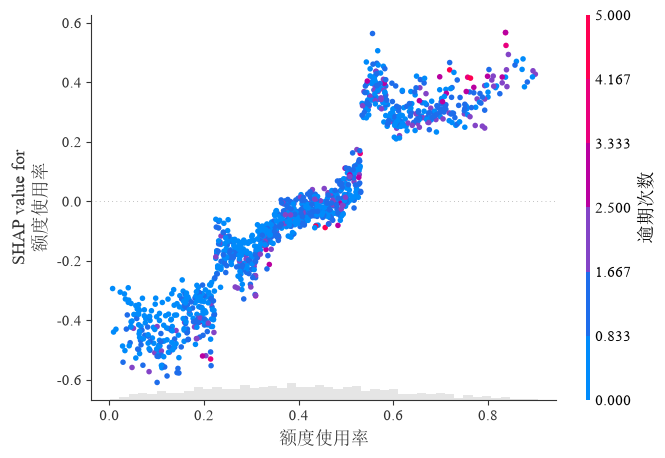

In [10]:
import shap
# 目的：绘制SHAP依赖散点图
# 横轴：额度使用率（特征本身取值）
# 纵轴：额度使用率对应的SHAP值（这个特征对模型logit打分的贡献）
# 颜色：逾期次数，用来观察【额度使用率】和【逾期次数】之间有没有交互
# 当前 shap 版本用 sv_m[:, '特征名'] 取单列
shap.plots.scatter(sv_m[:, '额度使用率'], color=sv_m[:, '逾期次数'])

先分清坐标轴：

- X 轴（横轴）：额度使用率，特征本身的数值，从 0 到 0.8
- Y 轴（纵轴：SHAP 值）：这个特征给模型打分加多少分（对数几率 logit）
  - SHAP>0（横线以上）：拉高逾期风险，推高违约概率
  - SHAP<0（横线以下）：压低逾期风险，降低违约概率
- 底部灰色直方图：每个额度区间有多少样本，看样本疏密
- 颜色条：逾期次数，蓝色 = 逾期少，红色 = 逾期多

整体趋势解读：

图里能看到一个清晰规律：

- 额度使用率低的时候，SHAP 大多是负数 → 低额度使用率，是减分项，利好客户；
- 额度使用率慢慢升高，SHAP 从负往正走；额度使用率很高时，SHAP 大多为正数 → 高额度使用率，是风险加分项，不利于客户

通俗说：用得越少，这个特征帮客户“降风险分”；用得越满，这个特征帮模型“判定风险更高”。

补充考点：树模型画出来不会是一条光滑直线，会有台阶、局部起伏，这是树分裂天然带来的

## 10.13 类别特征怎么看

类别特征（分类特征），比如【职业】：公职、互联网、制造业、餐饮零售、个体经营

这类标签没有天然大小顺序，不能分箱、不能谈单调！

比如你不能说“公职 < 互联网 < 制造业”，职业之间没有大小，所以不能用之前的单调性代码

按类别分组，算每个类别里面所有人的平均 SHAP 值，画横向条形图对比

例子：

模型用来预测“会不会迟到”，特征是【通勤方式】：步行、公交、地铁、打车。

通勤方式没有大小顺序。

我们算每一类人的平均 SHAP

- 打车：平均 SHAP = -0.5 → 打车这个特征，平均上会降低迟到概率
- 步行：平均 SHAP = +0.4 → 步行这个特征，平均上会拉高迟到概率

误差线代表：同一种通勤方式里，人和人差别很大。比如同样打车，有的人出门很早（SHAP 很低），有的人卡点出门（SHAP 偏高）

连续特征：看从小到大的趋势、单调性；类别特征：看不同类别各自平均贡献，横向对比谁拉高、谁拉低模型输出

这个图只是模型在这批样本上的归因，不是给职业贴好坏标签！

不是说个体经营的人本身风险高，只是在当前这份数据、当前这个模型里，“个体经营”这个标签，平均上推高违约分数。

不能拿去直接对外宣传、歧视性描述

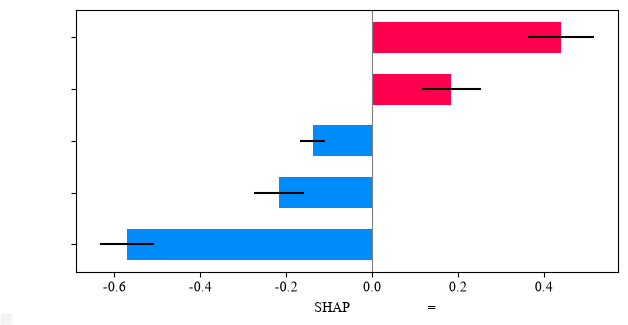

In [11]:
# 目的：计算类别特征（这里是职业）每个类别下客户的平均SHAP值，画横向条形图

# 1. 找到特征名字叫“职业”在SHAP解释对象sv_m里面对应的下标
j = list(sv_m.feature_names).index('职业')

# 2. 把测试集的职业标签 和 这条样本对应的【职业这个特征的SHAP值】拼成一张表
tab = pd.DataFrame({
    "职业":X_test['职业'].to_numpy(),
    "Shap": sv_m.values[:,j]
})

# 3. 按职业分组，对SHAP值聚合统计:均值mean、标准差std、样本数量size
tab = tab.groupby("职业")['Shap'].agg(['mean','std','size']).sort_values('mean')

# tab_1
# 6. 创建画布，figsize：宽7英寸，高3.4英寸
fig,ax = plt.subplots(figsize=(7,3.4))

# 7. 画横向条形图barh
# tab.index：纵轴，也就是各个职业名称
# tab["mean"]：横轴，每个职业的平均SHAP
# xerr=tab["std"]：加上横向误差线，长度等于这个类别里SHAP的标准差
# height=0.6：条形粗细

# np.where：判断，如果平均SHAP>0 → 红色（正向贡献，推高风险）；小于0 → 蓝色（负向贡献，拉低风险）
ax.barh(tab.index,tab['mean'],xerr=tab['std'],height=0.6,color=np.where(tab['mean']>0,'#ff0051','#008bfb'))

# 8. 画一条灰色竖线 x=0，作为分界线
ax.axvline(0,color='gray',lw=0.8)

# 9. 设置横轴标签，告诉看图人：误差线是标准差
ax.set_xlabel("该类别客户的平均 SHAP 值（误差线 = 标准差）")

# 10. 展示图片
plt.show()

## 10.14 瀑布图

前面我们看的都是全局视角：

- bar 图：所有客户整体上，哪个特征最重要
- 依赖图：看全体样本，特征取值和 SHAP 的趋势
- 类别条形图：一类客户平均贡献
- 聚类图：看一组相关特征

但是业务上风控最常被问：这个客户单独这一笔，为什么被拒？

全局图回答不了这个问题，我们需要单样本解释，也就是 waterfall 瀑布图

全局 SHAP 看“特征重要不重要”；waterfall 瀑布图看这一个客户，每一项特征分别是帮他加分（更容易通过）还是扣分（更容易拒贷）

违约概率 0.05 ;特征： {'年龄': 42, '月收入': 6700, '负债收入比': 0.496, '额度使用率': 0.163, '逾期次数': 0, '工作年限': 3.2, '学历': '硕士及以上', '住房': '有房贷', '职业': '公职'}


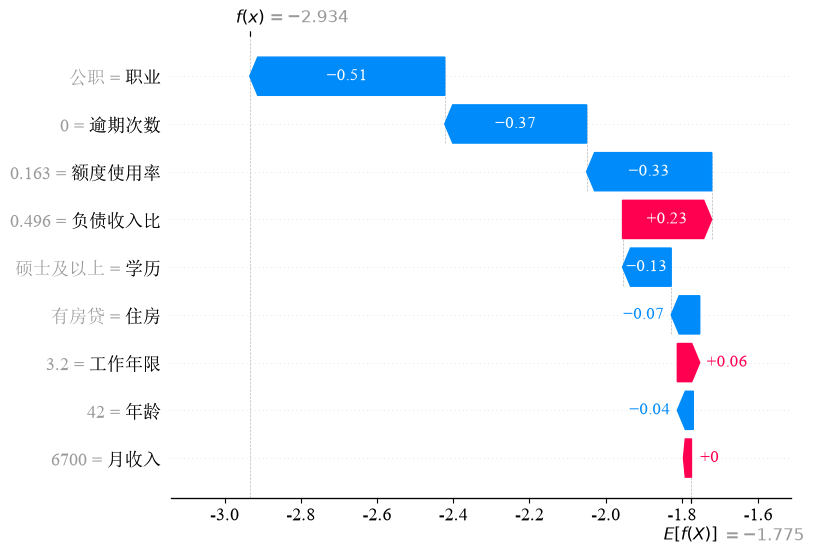

In [12]:
# 目的：对【单独一个客户】做模型解释，画SHAP瀑布图waterfall

# 1. 指定我们要解释的客户在测试集里的下标（从0开始计数）
i = 1169

# 2. 打印两件信息：这个客户的违约概率、他所有特征的取值
print("违约概率",round(float(p_test[i]),3),";特征：",X_test.iloc[i].to_dict())

# 3. 画瀑布图 waterfall
shap.plots.waterfall(sv_m[i],max_display=10)

瀑布图读图讲解：

- 最底部：E[f(X)] = -1.775
  - 基准值：全部测试样本的平均对数几率。相当于所有人的“起点分”
- 每一行台阶：取值=特征名，后面数字是这个特征的 SHAP 值
  - 红色条：正数 SHAP，向右推高对数几率 → 拉高违约概率，对客户不利，是拒贷负面因素
  - 蓝色条：负数 SHAP，向左拉低对数几率 → 降低违约概率，对客户有利，是加分项
- 最顶端：f(x) = -2.934
  - 叠加完所有特征贡献之后，这个客户最终的对数几率

这个客户逐条拆解：（例如下面介绍）

- 月收入 3100：+0.64，本次最大负面因素，大幅拉高风险
- 逾期次数 2 次：+0.54，第二大负面因素
- 职业 = 个体经营：+0.48，第三大负面因素
- 住房 = 全款房：-0.22，最大加分项，帮他压低风险
- 负债收入比 0.398：+0.17，负面
- 学历高中及以下：+0.12，负面
- 工作年限 6.7 年：+0.07，轻微负面
- 年龄 50 岁：-0.04，小幅加分
- 额度使用率 0.471：+0.01，影响很小

总结：虽然全款房、年龄给他带来一点利好，但是收入偏低、有逾期记录、个体经营这三个负面因素太强，把分数顶上去，违约概率超过审批线，被拒

## 10.15 decision 图：审批线附近的多笔对比

前面的 waterfall 图，一次只能看 1 个客户，适合单个客户的逐因子拆解

但风控审批最头疼的是边缘样本：违约概率刚好卡在审批分数线附近（cutoff=0.30），有的客户是多个小问题叠加，有的客户是某一项硬伤直接拉到红线

decision 图的价值：一张图同时看一批边缘客户，对比他们走向最终评分的路径

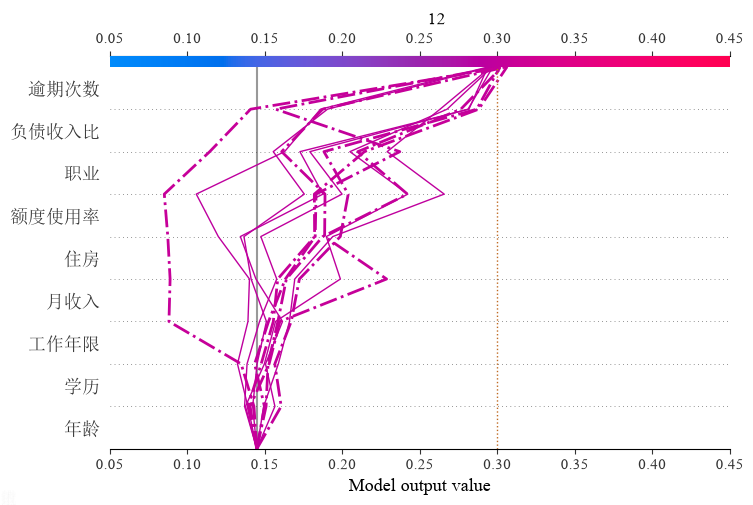

In [13]:
# 目的：多客户横向对比。筛选违约概率离审批线0.30最近的12个申请人
# 这些客户最终得分都卡在红线附近，但每个特征贡献的路径完全不一样
cutoff = 0.30

# 1. 计算每个样本的预测概率和审批线0.30的绝对距离，从小到大排序，取前12个
# 重点：不是挑概率最高的，是挑离0.30最近的边缘样本
idx = np.argsort(np.abs(p_test - cutoff))[:12]

# 2. 绘制shap decision图
# base_values：基准值；sv_m.values[idx]：选中12个样本的SHAP值
# features：对应样本原始特征；feature_names：特征名称
# link="logit"：把内部累加的对数几率，换算成概率刻度展示（只是改显示刻度，不是重新算概率空间SHAP）
# highlight：把最终概率≥0.30（被拒绝）的样本标记出来，画虚线
# xlim：横轴显示范围；title：图标题；show=False：先不弹窗，方便后续加线条
shap.plots.decision(float(sv_m.base_values[0]), sv_m.values[idx], features=X_test.iloc[idx],
                    feature_names=list(sv_m.feature_names), link="logit",
                    highlight=np.where(p_test[idx] >= cutoff)[0],
                    xlim=(0.05, 0.45), title="审批线附近的12位申请人", show=False)

# 3. 画审批竖线，和图上概率刻度保持单位一致
# 重要提醒：link="logit"之后横轴已经是概率，不能直接在原始对数几率坐标上画0.3
plt.axvline(cutoff, color="#C06A22", ls=":", lw=1)
plt.show()

## 10.16 force 图（SHAP 力图）

waterfall 是阶梯式竖向累加，decision 是多条样本轨迹对比；

force 图和 waterfall 解释的是同一个客户、同一套 SHAP 贡献，只是可视化形式改成横向一条带子

例子：

把 waterfall 一层一层的台阶，横向压扁成一条数轴。

基准分在中间，红色块向右推高风险、蓝色块向左拉低风险，推和拉博弈之后，落点就是这个客户最终得分。

就像拔河：红色一方往右拉、蓝色一方往左拉，平衡点就是最终预测结果

findfont: Failed to find font weight bold for SimSun, now using 400.


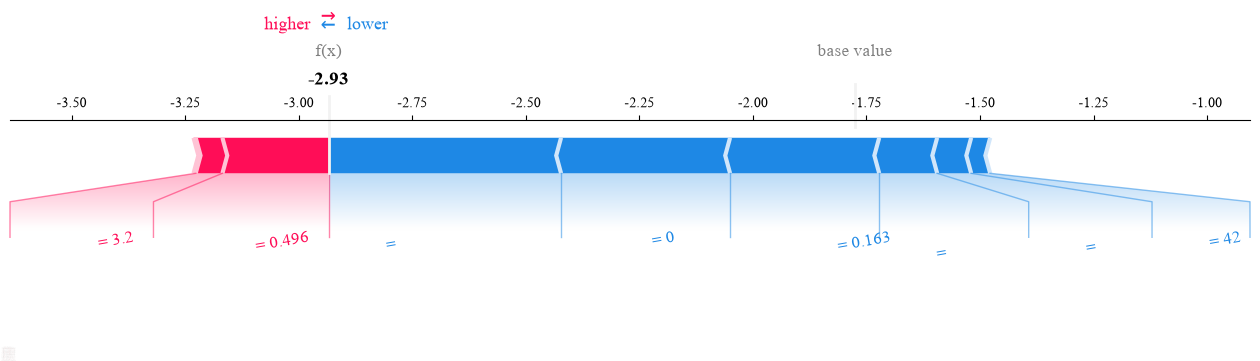

In [14]:
# 目的：force力图，和waterfall表达同一个客户的SHAP贡献，横向带状展示
# matplotlib=True 输出静态图片，适合放到报告、word文档里；交互式版本需要JS
# contribution_threshold 只控制标签要不要显示，不会删掉特征本身的贡献
shap.plots.force(sv_m[i],
                 matplotlib=True,        # 开启matplotlib静态图模式（不是交互式js）
                 figsize=(16, 3),        # 设置画布大小：宽16英寸，高3英寸，长条横向图
                 text_rotation=10,       # 文字标签旋转10度，防止文字挤在一起重叠
                 contribution_threshold=0.04, # 贡献绝对值大于0.04才显示文字标签，小贡献不标文字
                 plot_cmap=["#C94E78", "#1F5FA6"], # 自定义配色：正向风险色、负向利好色
                 show=False)             # 先不弹窗，方便后续保存图片

# 保存静态force图到指定文件夹；交互式版本不能直接存成图片
plt.savefig(OUTPUT_DIR / f"图_force_{i}.png")
plt.show()

# 下面是补充的交互式版本写法（Notebook里面用）
# shap.initjs()               # 初始化js环境，用来渲染交互式force图
# shap.plots.force(sv_m[i])   # 单样本交互式力图，鼠标悬浮看详情

# 多人叠加交互式版本：把一批样本的force叠在一起，还可以自动按相似度排序
# shap.plots.force(sv_m[:300])
# shap.save_html("force.html", shap.plot) # 导出成独立网页文件发给别人打开